In [1]:
import numpy as np
import math
import matplotlib.pyplot as plt
from scipy import signal

A = np.zeros(801) # passa-baixas
B = np.zeros(801) # passa-altas
H = np.zeros(801) # filtro final rejeita-banda

pi = 3.1415926
M = 800
fs = 1000.0

#Filtro A -> lowpass
FC = 0.196
for i in range(801):
    if (i - M / 2) == 0:
        A[i] = 2 * pi * FC
    else:
        A[i] = math.sin(2 * pi * FC * (i - M / 2)) / (i - M / 2)
    # Janela de Blackman
    A[i] = A[i] * (0.42 - 0.5 * math.cos(2 * pi * i / M) + 0.08 * math.cos(4 * pi * i / M))

soma = sum(A)
for i in range(801):
    A[i] = A[i] / soma

#Filtro B -> highpass
FC = 0.204
for i in range(801):
    if (i - M / 2) == 0:
        B[i] = 2 * pi * FC
    else:
        B[i] = math.sin(2 * pi * FC * (i - M / 2)) / (i - M / 2)
    # Janela de Blackman
    B[i] = B[i] * (0.42 - 0.5 * math.cos(2 * pi * i / M) + 0.08 * math.cos(4 * pi * i / M))

soma = sum(B)
for i in range(801):
    B[i] = B[i] / soma

# Inversão Espectral (Transforma o B em Passa-altas)
for i in range(801):
    B[i] = -B[i]
B[400] = B[400] + 1

#Soma A e B -> filtro rejeita-faixa
for i in range(801):
    H[i] = A[i] + B[i]

In [2]:
#########GERANDO ARQUIVO .HEX COM OS COEFICIENTES DO FILTRO#########

#resolução do  hardware 
N_BITS = 16 #tamanho do dado do array_coeficientes

# Fator de escala: para 16 bits com sinal, o valor máximo é 32767 (2^15 - 1)
fator_escala = (2**(N_BITS - 1)) - 1 

#Quantização -> Tr nsforma os floats de -1 a 1 em inteiros de -32767 a 32767)
H_inteiro = np.round(H * fator_escala).astype(int)

#Cria e escreve no arquivo .hex
with open("coeficientes_bandstop.hex", "w") as arquivo:
    for coef in H_inteiro:
        valor_hex = coef & 0xFFFF 
        arquivo.write(f"{valor_hex:04X}\n")

print("Arquivo 'coeficientes_bandstop.hex' gerado com sucesso!")

Arquivo 'coeficientes_bandstop.hex' gerado com sucesso!


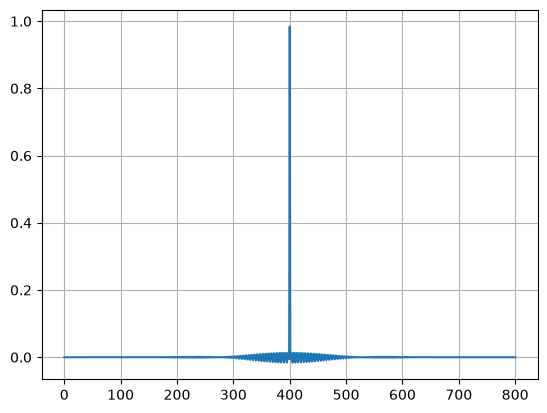

In [3]:
#########PLOTANDO OS COEFICIENTES DO FILTRO#########
plt.plot(H)
plt.grid()

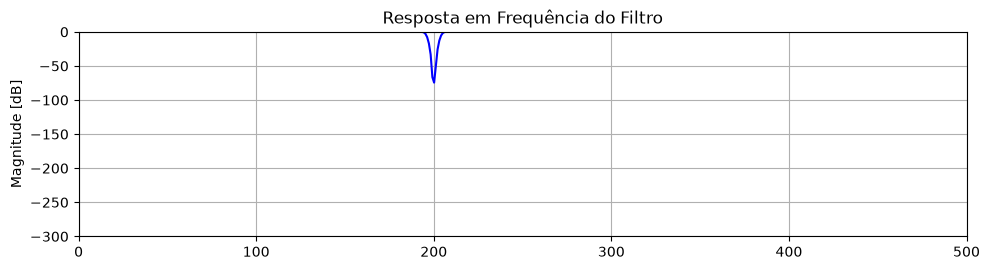

In [4]:
#########PLOTANDO A RESPOSTA EM FREQUÊNCIA DO FILTRO#########

# 2. Calcule a resposta em frequência (w = frequências, h = resposta complexa)
w, h = signal.freqz(H, 1, fs=fs)

# 3. Plote o gráfico da Magnitude (ganho em dB) e da Fase
plt.figure(figsize=(10, 5))

# Subplot da Magnitude
plt.subplot(2, 1, 1)
plt.plot(w, 20 * np.log10(np.abs(h)), "b")
plt.title("Resposta em Frequência do Filtro")
plt.ylabel("Magnitude [dB]")
plt.xlim(0, 500)
plt.ylim(-300, 0)


plt.grid()

# Subplot da Fase
'''plt.subplot(2, 1, 2)
plt.plot(w, np.unwrap(np.angle(H)) * (180 / np.pi), "r")
plt.xlabel("Frequência [Hz]")
plt.ylabel("Fase [graus]")
plt.xlim(0, 1200)

plt.grid()'''


plt.tight_layout()
plt.show()
